## MTL Trajet: 10 Temperature Mode Distance Speed Patterns (Flag 10)

### Dataset Overview
Monday-to-Friday urban trajectories with temperature, travel mode, distance, average point speed, and timestamped GPS-point records.

The notebook exposes a primary table and a supporting table (`trajectory_points.csv`).

Goal: Analyze how weekday mobility patterns vary with temperature.

Role: Urban mobility and weather analyst


Category: Weekday temperature, transport mode, trip distance, and point-speed patterns

### Your Objective
Use the provided tables and visual evidence to answer the questions below and summarize the observed trajectory patterns.


## Import Necessary Libraries

This cell loads the data-analysis and visualization libraries used by the questions below.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, SVG, display

## Load Dataset

The primary table is loaded into `df`; when available, the supporting trajectory or driver table is loaded into `user_df`.

In [ ]:
dataset_path = "trajectories.csv"
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv(dataset_path)

In [ ]:
user_dataset_path = "trajectory_points.csv"
user_df = pd.read_csv(user_dataset_path)

### **Question 1**: How do weekday transport-mode shares vary with temperature?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

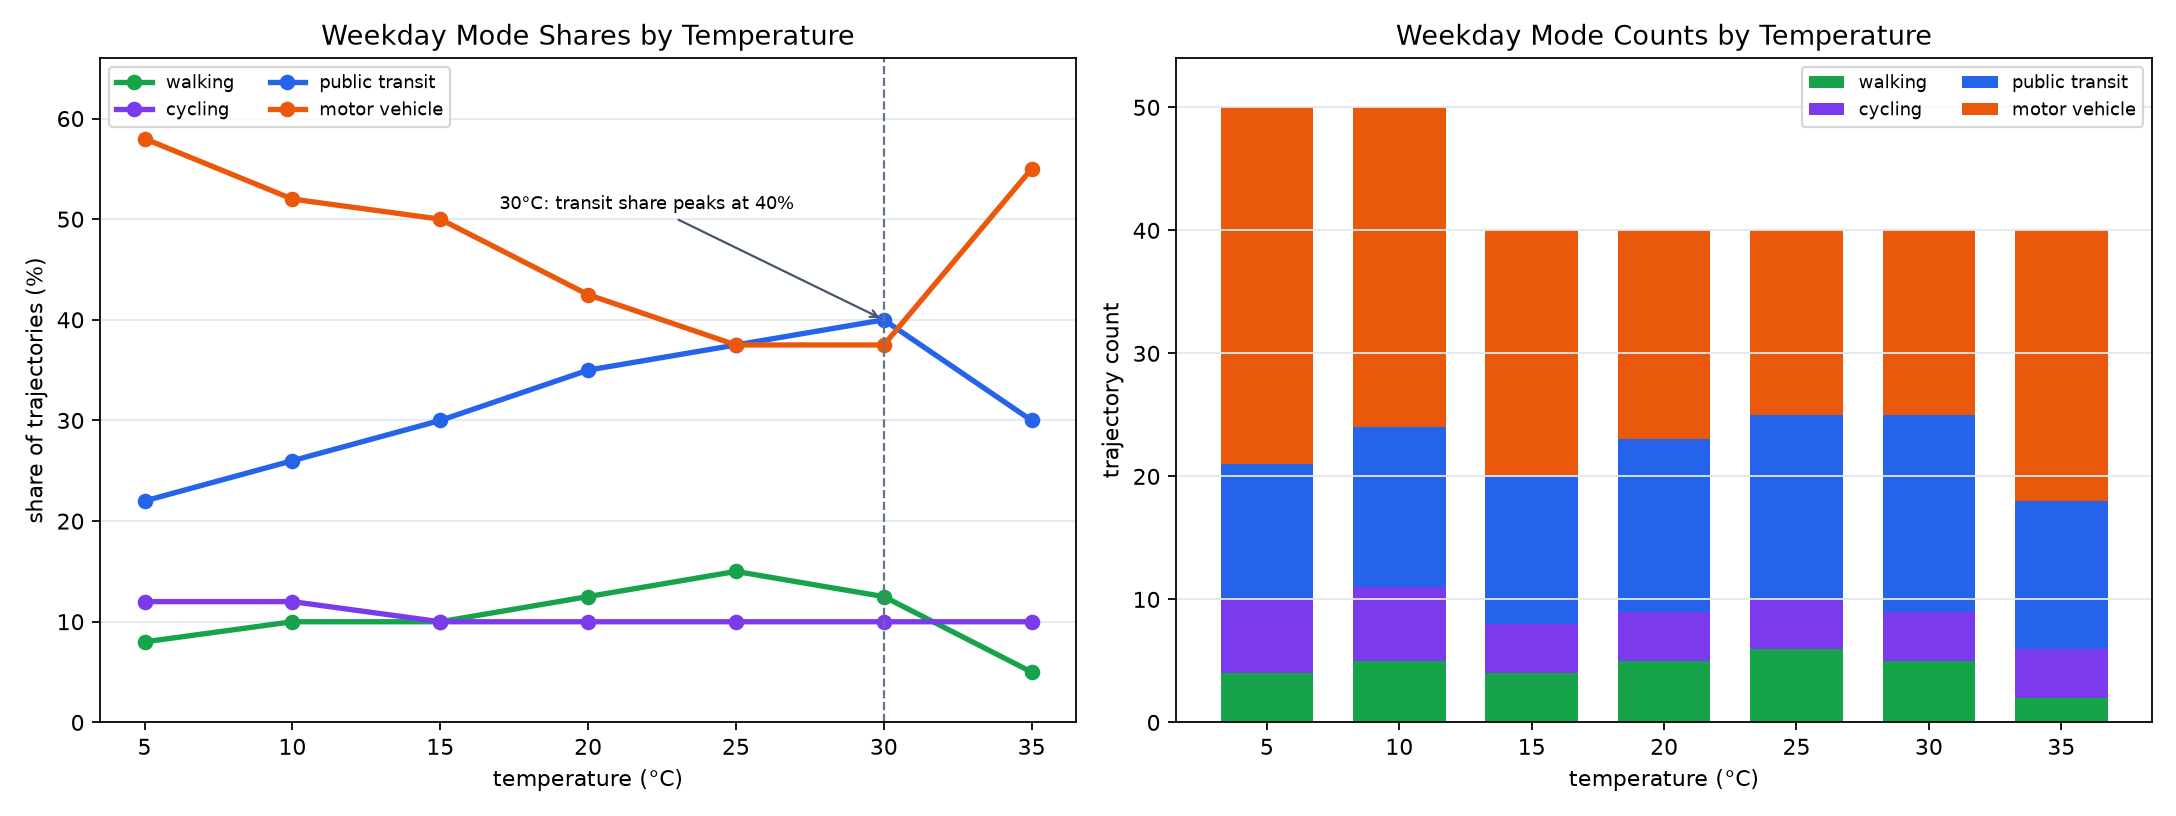

In [ ]:
pd.crosstab(df.temperature_c, df.mode_group, normalize='index')
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/mode_share_by_temperature.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Medium (4 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "weekday_temperature_mode_composition",
  "insight": "The share of public-transit trajectories increases as temperature rises, but declines in the hottest conditions as the share of motor-vehicle trajectories increases. Cycling maintains a relatively small and stable share across temperature conditions.",
  "insight_type": "factor_relationship",
  "plot": {
    "plot_type": "trajectory_comparison",
    "title": "Mode Share by Temperature",
    "description": "The plot is generated from the supplied case tables.",
    "file": "visualizations/mode_share_by_temperature.png"
  },
  "question": "How do weekday transport-mode shares vary with temperature?",
  "code": "pd.crosstab(df.temperature_c, df.mode_group, normalize='index')",
  "difficulty_level": 4,
  "difficulty_label": "medium",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "temperature",
    "transport_mode",
    "trajectory_id",
    "trajectory_timestamp"
  ]
}

### **Question 2**: At lower temperatures, how much do walking, cycling, and motor-vehicle distance distributions overlap?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

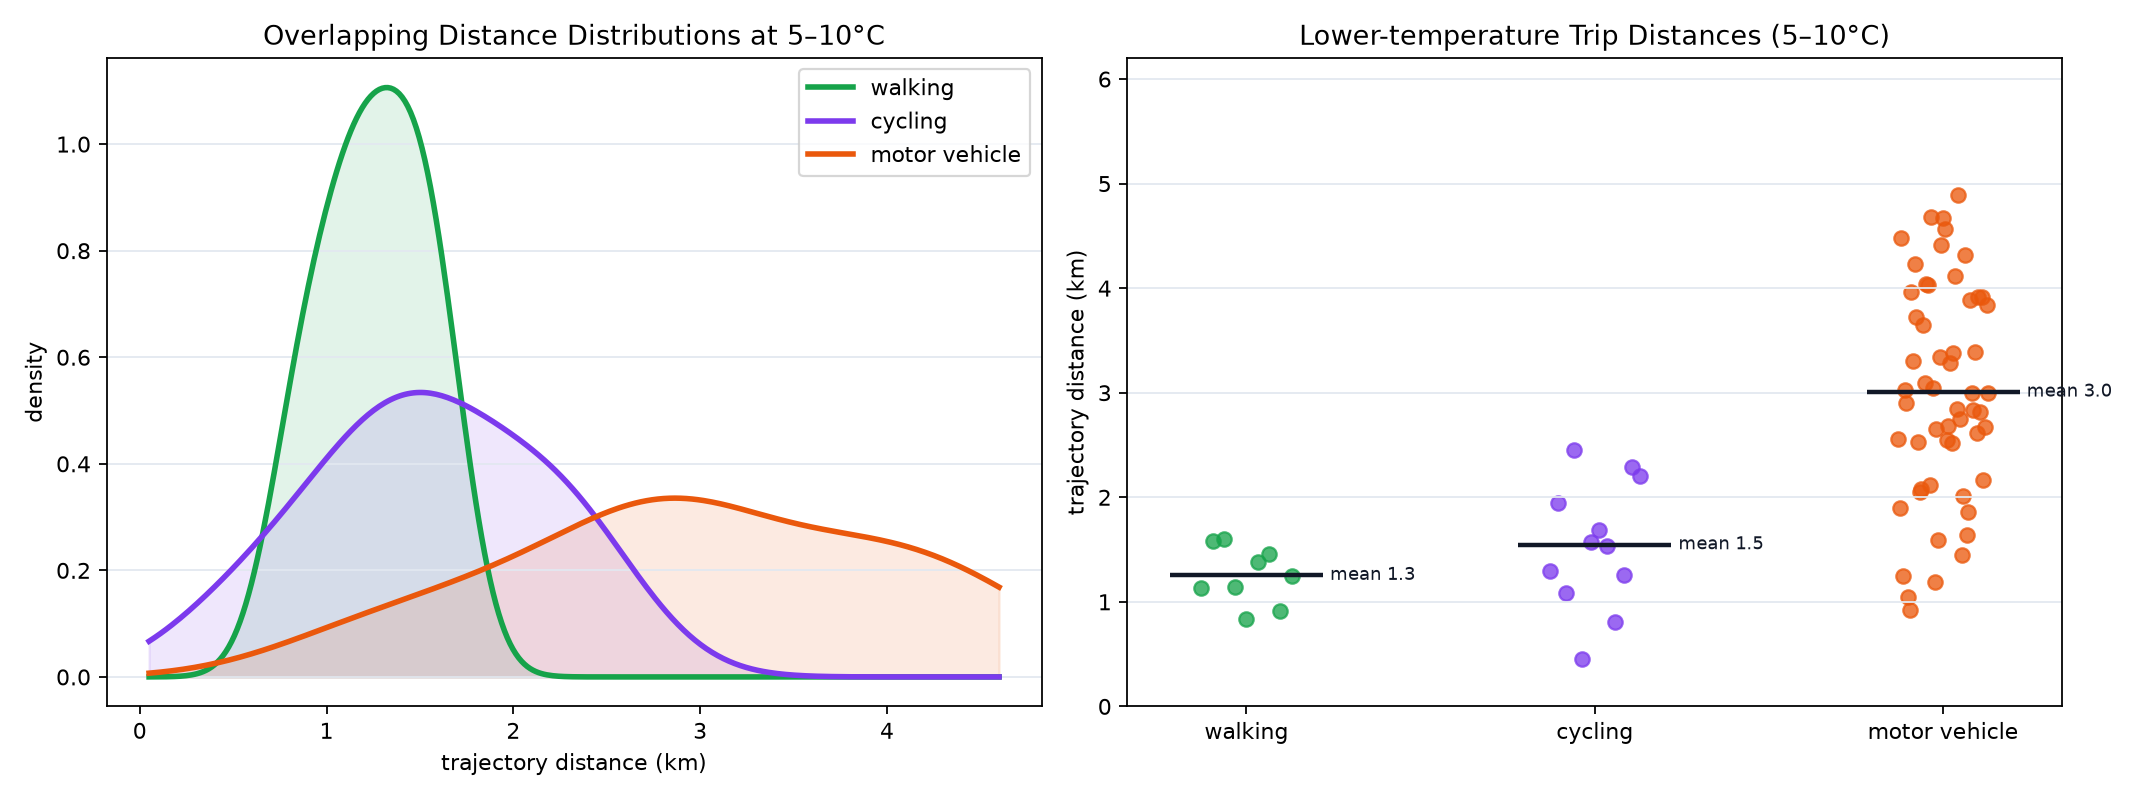

In [ ]:
df[df.temperature_c.le(10)].groupby('mode_group').distance_km.describe()
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/distance_by_mode_temperature.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Medium (4 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "low_temperature_distance_overlap",
  "insight": "At lower temperatures, the distance distributions of walking, cycling, and motor-vehicle trips partially overlap.",
  "insight_type": "group_comparison",
  "plot": {
    "plot_type": "trajectory_comparison",
    "title": "Distance Distributions at Low Temperature",
    "description": "The plot is generated from the supplied case tables.",
    "file": "visualizations/distance_by_mode_temperature.png"
  },
  "question": "At lower temperatures, how much do walking, cycling, and motor-vehicle distance distributions overlap?",
  "code": "df[df.temperature_c.le(10)].groupby('mode_group').distance_km.describe()",
  "difficulty_level": 4,
  "difficulty_label": "medium",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "temperature",
    "transport_mode",
    "gps_position",
    "trajectory_id"
  ]
}

### **Question 3**: How does average point speed vary with temperature across transportation modes?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

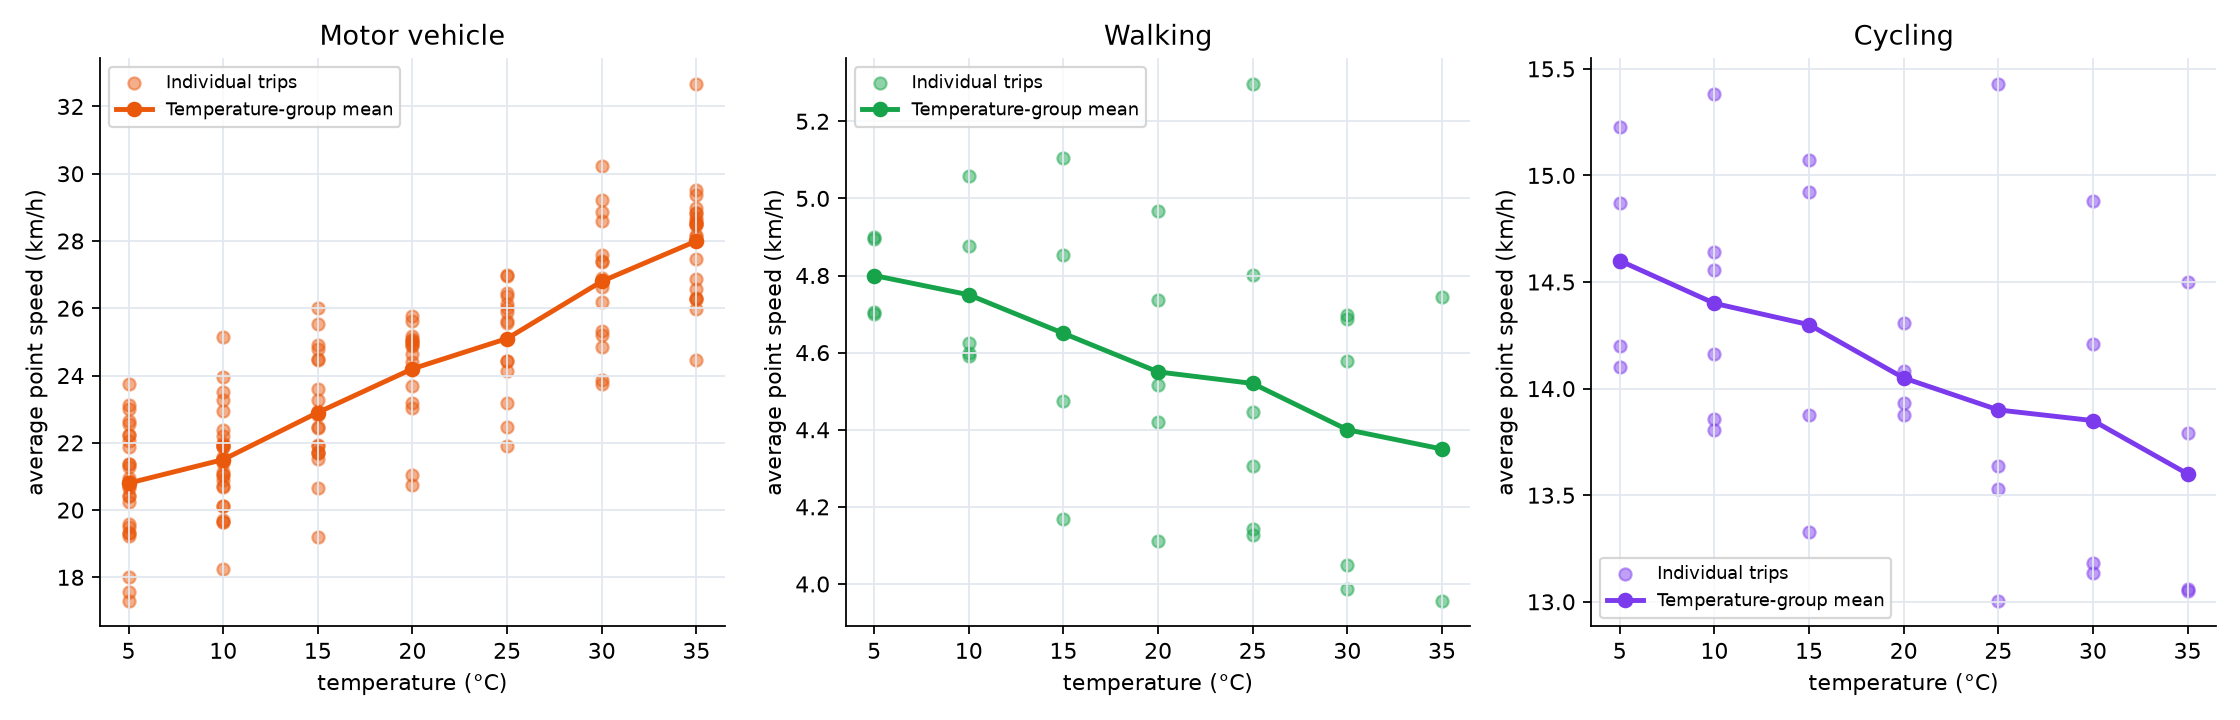

In [ ]:
df.groupby(['temperature_c','mode_group']).avg_point_speed_kmh.mean()
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/speed_by_mode_temperature.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Medium (4 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "temperature_speed_mode_trend",
  "insight": "As temperature rises, average motor-vehicle speed increases, while walking and cycling speeds decrease slightly.",
  "insight_type": "factor_relationship",
  "plot": {
    "plot_type": "trajectory_comparison",
    "title": "Speed by Temperature and Mode",
    "description": "The plot is generated from the supplied case tables.",
    "file": "visualizations/speed_by_mode_temperature.png"
  },
  "question": "How does average point speed vary with temperature across transportation modes?",
  "code": "df.groupby(['temperature_c','mode_group']).avg_point_speed_kmh.mean()",
  "difficulty_level": 4,
  "difficulty_label": "medium",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "temperature",
    "transport_mode",
    "point_speed",
    "trajectory_id"
  ]
}

### Summary of Findings (Flag 10)

The share of public-transit trajectories increases as temperature rises, but declines in the hottest conditions as the share of motor-vehicle trajectories increases. Cycling maintains a relatively small and stable share across temperature conditions. At lower temperatures, walking, cycling, and motor-vehicle distance distributions partially overlap, while average motor-vehicle speed increases with temperature and walking and cycling speeds decrease slightly.